### Sliding Window Research for Wind Offshore Forecasting

In this notebook, I compare how much recent history a model needs and how often it should be retrained in prod. The target is the German offshore wind **capacity factor**, using the 14-point interpolated feature set selected in notebook 3.

A **365/7** regime means fitting a new model on the latest 365 calendar days of available history, then keeping its parameters fixed for seven target days. New weather forecasts still arrive each day: a seven-day validation block does **not** mean making a seven-day weather forecast at its start.

I compare LightGBM, XGBoost, and CatBoost across history windows of **60, 90, 180, 270, 365, and 400 days**, with retraining intervals of **1, 7, 14, and 28 days**. This gives **72** configurations. The training window upper bound is set to 400 days to preserve at least a full year of out-of-sample data for fair validation across all setups. This ensures that even with a 28-day retraining cycle, a 400-day window allows the model to "see" the exact same 4-week seasonal block from the previous year. The settings below are fixed, moderately regularized baselines.

The primary objective is not merely to optimize for pure accuracy, but to identify a regime that yields acceptable metrics with low validation variance. At this stage, the OOF predictions are expected to serve as inputs for a downstream price meta-model, making consistency the top priority. This is precisely why I evaluate a **sliding window rather than an expanding window** approach.

In [1]:
# Core imports and project paths
import hashlib
import json
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyrootutils
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
from IPython.display import display
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import os
from dotenv import load_dotenv

load_dotenv()

# Setting up project root
PROJECT_ROOT = pyrootutils.setup_root(
    search_from=__file__ if "__file__" in locals() else ".",
    indicator=".gitignore", pythonpath=True,
)

# Import a function to get the number of available CPU threads
from utils.utils_for_notebooks import get_available_threads

# Setting up paths
DATASET_PATH = PROJECT_ROOT / "data/datasets/offshore_dataset_15m_interpolated_14_points_proxy_2024-03-14_to_2026-06-11.parquet"
RESULTS_ROOT = PROJECT_ROOT / "results" / "wind_offshore_window_research"

# Setting pandas display options
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:.5f}")


# Defining parameters for the experiments
TRAIN_WINDOWS = [60, 90, 180, 270, 365, 400]
RETRAIN_INTERVALS = [1, 7, 14, 28]
MODEL_NAMES = ["LightGBM", "XGBoost", "CatBoost"]
SEED = 1337

# Defining constants
N_THREADS = get_available_threads()
BOOSTING_ROUNDS = 200
HOLDOUT_DAYS = int(os.getenv("HOLDOUT_DAYS") or 28)
DAY_AHEAD_DEADLINE_HOUR = 12  # Berlin time on D-1
MAE_RELATIVE_MARGIN = 0.01
HIGH_CF_THRESHOLD = 0.6
REUSE_CACHE = True

# Printing library versions and available threads
VERSIONS = {"lightgbm": lgb.__version__, "xgboost": xgb.__version__,
            "catboost": cb.__version__, "pandas": pd.__version__, "numpy": np.__version__}
print("Library versions:", VERSIONS)
print(f"Model threads available to this process: {N_THREADS}")

Library versions: {'lightgbm': '4.6.0', 'xgboost': '3.3.0', 'catboost': '1.2.10', 'pandas': '3.0.2', 'numpy': '2.4.4'}
Model threads available to this process: 16


### Loading the selected dataset

As in notebook 3, absolute timestamps, actual generation, installed capacity, and the target are excluded from the features. Weather trajectory features such as `delta_after` are allowed only because they describe forecasts already issued, rather than future observations.

In [2]:
# Defining constants for the dataset
TARGET = "capacity_factor"
TARGET_TIME = "dt_berlin" # For splitting and evaluation
ISSUE_TIME = "dt_run_utc"
NON_FEATURES = {TARGET, TARGET_TIME, ISSUE_TIME, "capacity", "gen_wind_off_act"}


df = pd.read_parquet(DATASET_PATH).reset_index(drop=True)
df[TARGET_TIME] = pd.to_datetime(df[TARGET_TIME], utc=True).dt.tz_convert("Europe/Berlin")
df[ISSUE_TIME] = pd.to_datetime(df[ISSUE_TIME], utc=True)
df = df.sort_values(TARGET_TIME).reset_index(drop=True)
FEATURES = [c for c in df.columns if c not in NON_FEATURES
            and pd.api.types.is_numeric_dtype(df[c])]
assert FEATURES and not (set(FEATURES) & NON_FEATURES)
assert not df[TARGET_TIME].duplicated().any(), "Target timestamps must be unique."
assert df[[TARGET_TIME, ISSUE_TIME]].notna().all().all()
assert np.isfinite(df[FEATURES + [TARGET]].to_numpy()).all()
target_utc = df[TARGET_TIME].dt.tz_convert("UTC")
assert (df[ISSUE_TIME] < target_utc).all()

# Naive local dates are used only to group rows into local calendar days.
days = df[TARGET_TIME].dt.tz_localize(None).dt.normalize()
calendar = pd.date_range(days.min(), days.max(), freq="D")
coverage = df.groupby(days).size().reindex(calendar, fill_value=0).rename("rows")
expected = pd.Series([
    int(((d + pd.Timedelta(days=1)).tz_localize("Europe/Berlin")
         - d.tz_localize("Europe/Berlin")) / pd.Timedelta(minutes=15))
    for d in calendar
], index=calendar)
print(f"Rows: {len(df):,} | Features: {len(FEATURES)}")
print(f"Target dates: {calendar.min().date()} to {calendar.max().date()}")
print(f"Missing calendar days: {(coverage == 0).sum()}")
print(f"Days with incomplete 15-minute coverage: {(coverage != expected).sum()}")
display(pd.DataFrame({"observed_rows": coverage, "expected_rows": expected})
        .loc[coverage != expected].head(10))

Rows: 78,620 | Features: 40
Target dates: 2024-03-15 to 2026-06-11
Missing calendar days: 0
Days with incomplete 15-minute coverage: 0


,observed_rows,expected_rows


### One common evaluation period for every regime

Short windows must not receive extra, earlier validation dates. I start the comparison only when the full 400-day history is available. Every configuration then predicts exactly the same rows, stopping before the last 28 calendar days.

Those last days are reserved for a later assessment after the regime and hyperparameters have been frozen. They are not scored here.

Setting the maximum training window to **400 days** leaves more than a **full year** for out-of-sample evaluation. This ensures that every configuration is tested across all four seasons under identical conditions, providing a balanced and season-agnostic comparison.

In production, I plan to publish the generation forecast before the day-ahead market closes at 12:00 Berlin time on D−1. By that moment, the 00Z ECMWF forecast for day D is available, and I can use complete generation history through the final 15-minute interval of D−2. The model is then used to predict the full day D, from 00:00 to 23:45. The simulation reproduces this timeline with a one-calendar-day gap between the end of the training history and the first target day.

The experiment assumes that the complete historical generation through D−2 is available for training. Missing or delayed production data belong to the production retraining pipeline: if a scheduled refit cannot be completed, the latest valid model should remain active.

All schedules start on the same evaluation date. A 7-day interval is an elapsed weekly schedule anchored there, not necessarily Sunday night. A 28-day interval is not a calendar month. The final refit block may be shorter, while all its observed days remain in the comparison.

Calendar offsets account for daylight-saving changes, so a history window is not always an exact multiple of 24 hours. The exact UTC boundaries of every refit are saved in `schedule_audit.csv`.

In [3]:
evaluation_end = calendar.max() + pd.Timedelta(days=1) - pd.Timedelta(days=HOLDOUT_DAYS)


def production_times_for_day(target_day):
    # The complete training history ends at D-1 00:00, after the final interval of D-2.
    training_cutoff = (target_day - pd.DateOffset(days=1)).tz_localize(
        "Europe/Berlin"
    )

    # The forecast is produced by the day-ahead market deadline at 12:00 on D-1.
    refit_time = training_cutoff + pd.Timedelta(hours=DAY_AHEAD_DEADLINE_HOUR)
    return training_cutoff.tz_convert("UTC"), refit_time.tz_convert("UTC")


def history_bounds(training_cutoff, train_days):
    # Use local calendar offsets; DST can change the corresponding UTC duration.
    cutoff = training_cutoff.tz_convert("Europe/Berlin")
    start = cutoff - pd.DateOffset(days=int(train_days))
    return start.tz_convert("UTC"), cutoff.tz_convert("UTC")


eligible_starts = []
for day in calendar[calendar < evaluation_end]:
    training_cutoff, _ = production_times_for_day(day)
    history_start, _ = history_bounds(training_cutoff, max(TRAIN_WINDOWS))
    if history_start >= target_utc.min():
        eligible_starts.append(day)

assert eligible_starts, "Insufficient history for the largest window and holdout."
evaluation_start = eligible_starts[0]
evaluation_index = np.flatnonzero(days.ge(evaluation_start) & days.lt(evaluation_end))
assert len(evaluation_index) > 0


def build_schedule(train_days, retrain_days):
    records = []
    for fold, start in enumerate(pd.date_range(
        evaluation_start, evaluation_end - pd.Timedelta(days=1), freq=f"{retrain_days}D"
    ), start=1):
        end = min(start + pd.Timedelta(days=retrain_days), evaluation_end)
        valid = np.flatnonzero(days.ge(start) & days.lt(end))
        if not len(valid):
            raise ValueError(f"Empty validation block: {start} to {end}")

        training_cutoff, refit_time = production_times_for_day(start)
        lower, upper = history_bounds(training_cutoff, train_days)
        train = np.flatnonzero(target_utc.ge(lower) & target_utc.lt(upper))

        # All weather features for the first target day come from a run issued
        # before the day-ahead prediction deadline.
        first_day_issue = df.loc[days.eq(start), ISSUE_TIME].max()

        assert lower >= target_utc.min(), "A regime lacks its full history span."
        assert len(train) and not np.intersect1d(train, valid).size
        assert target_utc.iloc[train].max() < training_cutoff
        assert first_day_issue < refit_time
        assert training_cutoff < refit_time < target_utc.iloc[valid].min()

        records.append(dict(
            fold=fold,
            train=train,
            valid=valid,
            refit_time=refit_time,
            history_start=lower,
            training_cutoff=upper,
            validation_start=start,
            validation_end=end,
            first_day_issue=first_day_issue,
        ))

    np.testing.assert_array_equal(
        np.concatenate([record["valid"] for record in records]),
        evaluation_index,
    )
    return records


schedules = {(h, r): build_schedule(h, r) for h in TRAIN_WINDOWS for r in RETRAIN_INTERVALS}
schedule_audit = pd.DataFrame([
    dict(train_days=h, retrain_days=r, **{k: v for k, v in f.items() if k not in {"train", "valid"}},
         n_train=len(f["train"]), n_valid=len(f["valid"]))
    for (h, r), folds in schedules.items() for f in folds
])
print(f"Common evaluation: {evaluation_start.date()} to {(evaluation_end - pd.Timedelta(days=1)).date()}")
print(f"Evaluation days: {days.iloc[evaluation_index].nunique()} | Rows: {len(evaluation_index):,}")
print(f"Reserved period: {evaluation_end.date()} to {calendar.max().date()}")
print(f"Total model fits: {len(schedule_audit) * len(MODEL_NAMES):,}")
display(schedule_audit.groupby(["train_days", "retrain_days"], as_index=False)
        .agg(refits=("fold", "size"), min_train_rows=("n_train", "min"), max_train_rows=("n_train", "max")))

Common evaluation: 2025-04-20 to 2026-05-14
Evaluation days: 390 | Rows: 37,440
Reserved period: 2026-05-15 to 2026-06-11
Total model fits: 8,784


,train_days,retrain_days,refits,min_train_rows,max_train_rows
0,60,1,390,5756,5764
1,60,7,56,5756,5764
2,60,14,28,5756,5764
3,60,28,14,5756,5764
4,90,1,390,8636,8644
5,90,7,56,8636,8644
6,90,14,28,8636,8644
7,90,28,14,8636,8644
8,180,1,390,17276,17284
9,180,7,56,17276,17284


### Fixed, moderately regularized models

I use 200 boosting rounds, a learning rate of 0.05, shallow trees, feature and row sampling, and regularization. These are simple research defaults, not HPO results. The libraries do not implement identical trees, so equal settings do not imply equal model capacity.

There is no early stopping against the outer validation block. The number of rounds is fixed before scoring, and each refit starts from scratch on its own history window. This also keeps the cost below a nested early-stopping search. Regularization reduces the risk of overfitting; it does not prove its absence. After choosing a regime, HPO should be performed inside chronological training splits and the final policy checked on later data.

I clip predictions to [0, 1] for all models, as in notebook 6, and retain the raw values for inspection. The primary metrics are in capacity-factor units: MAE of 0.01 means one percentage point.

In [4]:
MODEL_PARAMS = {
    "LightGBM": dict(n_estimators=BOOSTING_ROUNDS, learning_rate=0.05,
        max_depth=4, num_leaves=15, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=5.0, random_state=SEED,
        n_jobs=N_THREADS, verbosity=-1),
    "XGBoost": dict(n_estimators=BOOSTING_ROUNDS, learning_rate=0.05,
        max_depth=4, min_child_weight=50, subsample=0.8,
        colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=5.0,
        objective="reg:squarederror", tree_method="hist", random_state=SEED,
        n_jobs=N_THREADS, verbosity=0),
    "CatBoost": dict(iterations=BOOSTING_ROUNDS, learning_rate=0.05,
        depth=4, l2_leaf_reg=5.0, bootstrap_type="Bernoulli", subsample=0.8,
        rsm=0.8, loss_function="RMSE", random_seed=SEED,
        thread_count=N_THREADS, allow_writing_files=False, verbose=False),
}
MODEL_CLASSES = {"LightGBM": lgb.LGBMRegressor, "XGBoost": xgb.XGBRegressor,
                 "CatBoost": cb.CatBoostRegressor}


def build_model(name):
    return MODEL_CLASSES[name](**MODEL_PARAMS[name])


def prediction_params(model_name):
    # Runtime-only settings do not change the statistical configuration.
    runtime_keys = {"n_jobs", "thread_count"}
    return {key: value for key, value in MODEL_PARAMS[model_name].items()
            if key not in runtime_keys}


# This identity describes the shared data and evaluation period. Adding candidates
# to the search grid does not change it and therefore does not hide valid caches.
study_manifest = dict(
    protocol="day-ahead-d-minus-one-gap-v4",
    dataset=str(DATASET_PATH),
    dataset_sha256=hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest(),
    features=FEATURES,
    versions=VERSIONS,
    holdout_days=HOLDOUT_DAYS,
    day_ahead_deadline_hour=DAY_AHEAD_DEADLINE_HOUR,
    evaluation_start=str(evaluation_start),
    evaluation_end=str(evaluation_end),
    clipping=[0, 1],
)
study_id = hashlib.sha256(
    json.dumps(study_manifest, sort_keys=True).encode()
).hexdigest()[:12]
OUTPUT_DIR = RESULTS_ROOT / study_id
CACHE_DIR = RESULTS_ROOT / "configuration_cache"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# The run manifest records the current grid for reproducibility, but the grid is
# deliberately excluded from the study and configuration cache identities.
run_manifest = dict(
    **study_manifest,
    train_windows=TRAIN_WINDOWS,
    retrain_intervals=RETRAIN_INTERVALS,
    model_params={name: prediction_params(name) for name in MODEL_NAMES},
    threads=N_THREADS,
    mae_relative_margin=MAE_RELATIVE_MARGIN,
    high_cf_threshold=HIGH_CF_THRESHOLD,
)
(OUTPUT_DIR / "manifest.json").write_text(
    json.dumps(run_manifest, indent=2), encoding="utf-8"
)
schedule_audit.to_csv(OUTPUT_DIR / "schedule_audit.csv", index=False)
print("Result directory:", OUTPUT_DIR)
print("Configuration cache:", CACHE_DIR)

Result directory: D:\python_projects\entsoe_1st_try\results\wind_offshore_window_research\ef7be447aa93
Configuration cache: D:\python_projects\entsoe_1st_try\results\wind_offshore_window_research\configuration_cache


### Running the deployment simulation

For each regime, the model stays fixed between refits. It receives each day's weather features as they arrive. Computing those predictions together is only a speed optimization: training never reads the validation rows or their labels.

The cache is stored **per configuration**. Its identity includes the dataset content, feature list, evaluation period, split protocol, library versions, model, model parameters, history window, and retraining interval. Adding another candidate window therefore trains only the new model/window/interval combinations. A change that can alter predictions invalidates only the affected configurations. CPU thread count and the full candidate lists are excluded because they do not define a configuration.

Cached files are validated against their metadata and expected evaluation rows before use. Partial files are ignored. An interrupted run can therefore resume safely. Fit times are descriptive wall-clock measurements from the run that created the cache, not a hardware-independent benchmark.

In [5]:
X = df[FEATURES].astype("float32")
y = df[TARGET].to_numpy()


def configuration_manifest(name, history, interval):
    # Each candidate has its own identity, independent of the rest of the grid.
    return dict(
        **study_manifest,
        model=name,
        model_params=prediction_params(name),
        train_days=int(history),
        retrain_days=int(interval),
    )


def cache_paths(name, history, interval):
    config = configuration_manifest(name, history, interval)
    config_id = hashlib.sha256(
        json.dumps(config, sort_keys=True).encode()
    ).hexdigest()[:16]
    prefix = CACHE_DIR / f"{name}_{history}_{interval}_{config_id}"
    return (
        prefix.with_name(prefix.name + "_predictions.parquet"),
        prefix.with_name(prefix.name + "_fits.csv"),
        prefix.with_name(prefix.name + "_manifest.json"),
        config,
    )


def validate_cached_tables(pred, fits):
    required_prediction_cols = {
        "row_id", "target_time", "issue_time", "actual", "raw_prediction",
        "prediction", "fold", "refit_time", *KEYS,
    }
    required_fit_cols = {"fold", "n_train", "n_valid", "fit_seconds", *KEYS}
    return (
        required_prediction_cols.issubset(pred.columns)
        and required_fit_cols.issubset(fits.columns)
        and np.array_equal(pred["row_id"].to_numpy(), evaluation_index)
        and pred["prediction"].between(0, 1).all()
    )


def load_cached_configuration(name, history, interval):
    prediction_path, fit_path, manifest_path, expected_manifest = cache_paths(
        name, history, interval
    )
    if not REUSE_CACHE:
        return None

    if not all(path.exists() for path in (prediction_path, fit_path, manifest_path)):
        return None

    cached_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    pred = pd.read_parquet(prediction_path)
    fits = pd.read_csv(fit_path)
    if cached_manifest == expected_manifest and validate_cached_tables(pred, fits):
        return pred, fits
    return None


def run_configuration(name, history, interval):
    cached = load_cached_configuration(name, history, interval)
    if cached is not None:
        return cached

    predictions, fit_records = [], []
    for split in schedules[(history, interval)]:
        train, valid = split["train"], split["valid"]
        model = build_model(name)
        started = time.perf_counter()
        model.fit(X.iloc[train], y[train])
        fit_seconds = time.perf_counter() - started
        raw = model.predict(X.iloc[valid])
        assert np.isfinite(raw).all()
        predictions.append(pd.DataFrame(dict(
            row_id=valid, target_time=df.iloc[valid][TARGET_TIME].to_numpy(),
            issue_time=df.iloc[valid][ISSUE_TIME].to_numpy(),
            actual=y[valid], raw_prediction=raw, prediction=np.clip(raw, 0, 1),
            fold=split["fold"], refit_time=split["refit_time"],
        )))
        fit_records.append(dict(fold=split["fold"], n_train=len(train),
                                n_valid=len(valid), fit_seconds=fit_seconds))
        if split["fold"] % 20 == 0:
            print(f"  {name} {history}/{interval}: refit {split['fold']}", flush=True)

    pred, fits = pd.concat(predictions, ignore_index=True), pd.DataFrame(fit_records)
    for table in (pred, fits):
        table["model"], table["train_days"], table["retrain_days"] = name, history, interval
    np.testing.assert_array_equal(pred["row_id"], evaluation_index)

    prediction_path, fit_path, manifest_path, config = cache_paths(name, history, interval)
    # Metadata is written last, so an interrupted write is never treated as complete.
    pred.to_parquet(prediction_path, index=False)
    fits.to_csv(fit_path, index=False)
    manifest_path.write_text(json.dumps(config, indent=2), encoding="utf-8")
    return pred, fits


KEYS = ["model", "train_days", "retrain_days"]
all_predictions, all_fits = [], []
for name in MODEL_NAMES:
    for history in TRAIN_WINDOWS:
        for interval in RETRAIN_INTERVALS:
            pred, fits = run_configuration(name, history, interval)
            all_predictions.append(pred)
            all_fits.append(fits)
            print(f"Completed {name:8s} | {history:3d}/{interval:2d} | "
                  f"MAE={mean_absolute_error(pred.actual, pred.prediction):.5f}", flush=True)
predictions = pd.concat(all_predictions, ignore_index=True)
fit_results = pd.concat(all_fits, ignore_index=True)
assert len(predictions) == len(evaluation_index) * len(MODEL_NAMES) * len(schedules)
assert not predictions.duplicated(KEYS + ["row_id"]).any()

  LightGBM 60/1: refit 20
  LightGBM 60/1: refit 40
  LightGBM 60/1: refit 60
  LightGBM 60/1: refit 80
  LightGBM 60/1: refit 100
  LightGBM 60/1: refit 120
  LightGBM 60/1: refit 140
  LightGBM 60/1: refit 160
  LightGBM 60/1: refit 180
  LightGBM 60/1: refit 200
  LightGBM 60/1: refit 220
  LightGBM 60/1: refit 240
  LightGBM 60/1: refit 260
  LightGBM 60/1: refit 280
  LightGBM 60/1: refit 300
  LightGBM 60/1: refit 320
  LightGBM 60/1: refit 340
  LightGBM 60/1: refit 360
  LightGBM 60/1: refit 380
Completed LightGBM |  60/ 1 | MAE=0.07131
  LightGBM 60/7: refit 20
  LightGBM 60/7: refit 40
Completed LightGBM |  60/ 7 | MAE=0.07485
  LightGBM 60/14: refit 20
Completed LightGBM |  60/14 | MAE=0.07585
Completed LightGBM |  60/28 | MAE=0.07557
  LightGBM 90/1: refit 20
  LightGBM 90/1: refit 40
  LightGBM 90/1: refit 60
  LightGBM 90/1: refit 80
  LightGBM 90/1: refit 100
  LightGBM 90/1: refit 120
  LightGBM 90/1: refit 140
  LightGBM 90/1: refit 160
  LightGBM 90/1: refit 180
  Lig

### Accuracy and stability on the same daily scale

Comparing the standard deviation of 1-day scores with that of 28-day scores would be misleading: longer blocks average out difficult days. Instead, I score **each calendar day** for every regime and report mean and sample standard deviation of MAE, RMSE, and R² on that common scale.

Daily R² can be very negative when actual generation barely varies. It is undefined for a constant target day; such days are excluded from its mean and standard deviation, and their valid count is reported. I use **mean daily MAE** as the primary accuracy metric, with daily MAE standard deviation and the 90th percentile to describe instability and difficult days. Signed daily bias helps reveal persistent over- or underprediction, which matters for a later price model.

Pooled metrics score all 15-minute rows together. They are useful context, but pooled RMSE and R² are not averages of daily scores. Days receive equal weight in daily means, while pooled metrics weight observed rows equally. Standard deviations describe temporal variation, not confidence intervals; neighboring days are correlated.

`high_cf_mae` is the pooled MAE for rows where the actual capacity factor is at least `0.6`. It uses the same clipped predictions and threshold as notebook 5. This metric shows how each operating regime performs during high offshore generation, where the earlier diagnostics found larger errors.

In [6]:
def metrics(frame):
    actual, predicted = frame.actual.to_numpy(), frame.prediction.to_numpy()
    return dict(mae=mean_absolute_error(actual, predicted),
                rmse=root_mean_squared_error(actual, predicted),
                r2=r2_score(actual, predicted) if len(actual) > 1 and np.var(actual) > 1e-12 else np.nan,
                bias=float(np.mean(predicted - actual)))

predictions["day"] = pd.to_datetime(predictions.target_time, utc=True).dt.tz_convert("Europe/Berlin").dt.tz_localize(None).dt.normalize()
daily = pd.DataFrame([
    dict(zip(KEYS + ["day"], key), **metrics(group), n_rows=len(group))
    for key, group in predictions.groupby(KEYS + ["day"], sort=True)
])
summary = daily.groupby(KEYS).agg(
    n_days=("day", "size"), mae_mean=("mae", "mean"), mae_std=("mae", "std"),
    mae_p90=("mae", lambda s: s.quantile(0.9)),
    rmse_mean=("rmse", "mean"), rmse_std=("rmse", "std"),
    r2_mean=("r2", "mean"), r2_std=("r2", "std"), r2_valid_days=("r2", "count"),
    bias_mean=("bias", "mean"), bias_std=("bias", "std"),
).reset_index()
pooled = pd.DataFrame([
    dict(zip(KEYS, key), **{f"{k}_pooled": v for k, v in metrics(group).items()})
    for key, group in predictions.groupby(KEYS)
])
high_cf = pd.DataFrame([
    {
        **dict(zip(KEYS, key)),
        "high_cf_mae": mean_absolute_error(
            group.loc[group.actual.ge(HIGH_CF_THRESHOLD), "actual"],
            group.loc[group.actual.ge(HIGH_CF_THRESHOLD), "prediction"],
        ) if group.actual.ge(HIGH_CF_THRESHOLD).any() else np.nan,
    }
    for key, group in predictions.groupby(KEYS)
])
cost = fit_results.groupby(KEYS).agg(
    n_refits=("fold", "size"), fit_seconds_total=("fit_seconds", "sum"),
    fit_seconds_mean=("fit_seconds", "mean"),
).reset_index()
summary = (
    summary
    .merge(pooled, on=KEYS, validate="one_to_one")
    .merge(high_cf, on=KEYS, validate="one_to_one")
    .merge(cost, on=KEYS, validate="one_to_one")
)
summary.insert(
    summary.columns.get_loc("mae_p90") + 1,
    "high_cf_mae",
    summary.pop("high_cf_mae"),
)
summary = summary.sort_values(["mae_mean", "mae_std"]).reset_index(drop=True)
summary["mae_gap_pct"] = 100 * (summary.mae_mean / summary.mae_mean.min() - 1)
assert len(summary) == len(MODEL_NAMES) * len(schedules) and summary.n_days.nunique() == 1
daily.to_csv(OUTPUT_DIR / "daily_metrics.csv", index=False)
summary.to_csv(OUTPUT_DIR / "summary.csv", index=False)
with pd.option_context("display.max_rows", 72):
    display(summary)

,model,train_days,retrain_days,n_days,mae_mean,mae_std,mae_p90,high_cf_mae,rmse_mean,rmse_std,r2_mean,r2_std,r2_valid_days,bias_mean,bias_std,mae_pooled,rmse_pooled,r2_pooled,bias_pooled,n_refits,fit_seconds_total,fit_seconds_mean,mae_gap_pct
0,LightGBM,400,1,390,0.06710,0.03738,0.12384,0.09682,0.08107,0.04216,-0.33947,2.35279,390,-0.00960,0.05554,0.06711,0.09137,0.84854,-0.00961,390,84.62263,0.21698,0.00000
1,CatBoost,180,1,390,0.06738,0.03510,0.11426,0.08042,0.08170,0.04117,-0.51378,4.48573,390,-0.00092,0.05487,0.06738,0.09147,0.84822,-0.00093,390,184.83956,0.47395,0.41204
2,XGBoost,365,1,390,0.06738,0.03752,0.12292,0.09554,0.08142,0.04255,-0.41204,3.01754,390,-0.00922,0.05610,0.06739,0.09186,0.84692,-0.00923,390,111.14312,0.28498,0.41411
3,CatBoost,270,1,390,0.06741,0.03556,0.11414,0.08798,0.08166,0.04176,-0.52802,4.08704,390,-0.00318,0.05556,0.06741,0.09170,0.84745,-0.00320,390,210.81976,0.54056,0.45557
4,XGBoost,400,1,390,0.06746,0.03787,0.12216,0.09841,0.08143,0.04271,-0.32995,2.23974,390,-0.01032,0.05603,0.06747,0.09193,0.84667,-0.01033,390,114.29076,0.29305,0.53093
5,XGBoost,180,1,390,0.06749,0.03549,0.11492,0.07987,0.08213,0.04167,-0.40526,2.96152,390,-0.00127,0.05509,0.06749,0.09207,0.84620,-0.00129,390,78.26888,0.20069,0.57242
6,LightGBM,365,1,390,0.06767,0.03708,0.12426,0.09523,0.08172,0.04200,-0.49152,4.56598,390,-0.00913,0.05556,0.06768,0.09187,0.84689,-0.00914,390,84.97739,0.21789,0.84896
7,LightGBM,180,1,390,0.06770,0.03552,0.11455,0.07991,0.08223,0.04164,-0.40425,3.25355,390,-0.00116,0.05557,0.06770,0.09215,0.84594,-0.00118,390,57.87424,0.14840,0.88938
8,LightGBM,270,1,390,0.06771,0.03619,0.11575,0.08486,0.08232,0.04235,-0.42430,3.07034,390,-0.00204,0.05684,0.06771,0.09255,0.84461,-0.00206,390,69.95798,0.17938,0.90093
9,XGBoost,270,1,390,0.06803,0.03561,0.11432,0.08475,0.08264,0.04177,-0.61718,5.03211,390,-0.00195,0.05715,0.06804,0.09258,0.84451,-0.00197,390,93.77583,0.24045,1.38273


### How history and retraining frequency change the result

The heatmaps use the same color scale across models. The first row shows mean daily MAE; the second shows its standard deviation. Lower values are better in both rows, but low variation alone is not enough: a model can be consistently inaccurate.

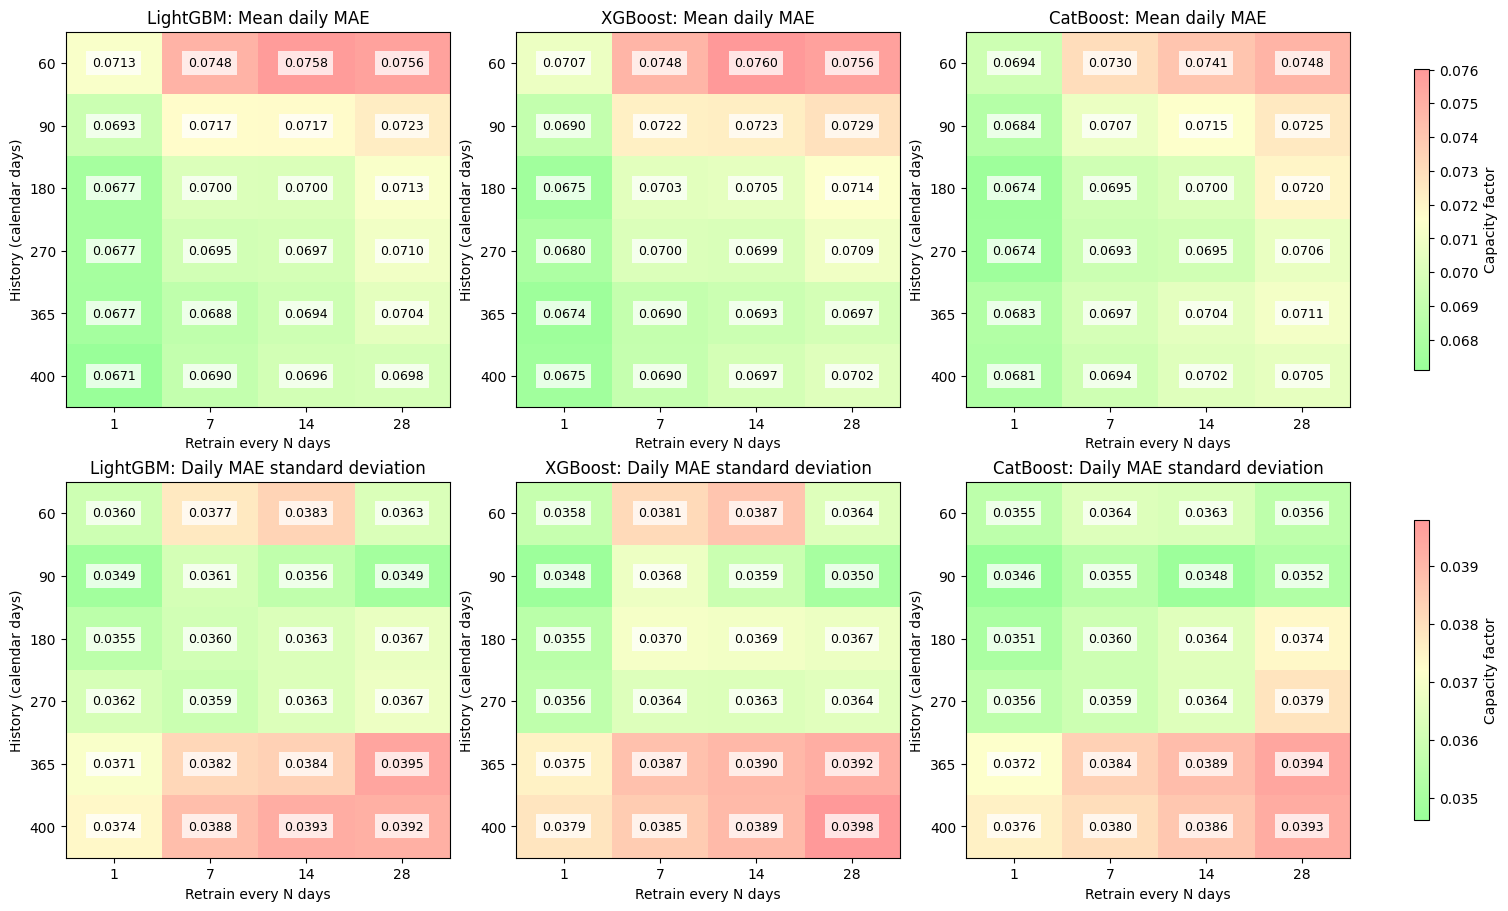

In [7]:
from matplotlib.colors import LinearSegmentedColormap

# Creating a custom colormap for the heatmaps
# Smaller is better (Green)
# Pastel green -> Pastel yellow -> Pastel red
light_pnl = LinearSegmentedColormap.from_list(
    "light_pnl", ["#99ff99", "#ffffcc", "#ff9999"]
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, (metric, title) in enumerate([("mae_mean", "Mean daily MAE"), ("mae_std", "Daily MAE standard deviation")]):
    low, high = summary[metric].min(), summary[metric].max()
    for col, name in enumerate(MODEL_NAMES):
        ax = axes[row, col]
        grid = summary.loc[summary.model.eq(name)].pivot(index="train_days", columns="retrain_days", values=metric).reindex(index=TRAIN_WINDOWS, columns=RETRAIN_INTERVALS)
        im = ax.imshow(grid, cmap=light_pnl, vmin=low, vmax=high, aspect="auto")
        ax.set_xticks(range(len(RETRAIN_INTERVALS)), RETRAIN_INTERVALS)
        ax.set_yticks(range(len(TRAIN_WINDOWS)), TRAIN_WINDOWS)
        ax.set_xlabel("Retrain every N days")
        ax.set_ylabel("History (calendar days)")
        ax.set_title(f"{name}: {title}")
        for i in range(len(TRAIN_WINDOWS)):
            for j in range(len(RETRAIN_INTERVALS)):
                ax.text(j, i, f"{grid.iloc[i, j]:.4f}", ha="center", va="center",
                        color="black", fontsize=9, bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"))
    fig.colorbar(im, ax=axes[row, :].tolist(), shrink=0.8, label="Capacity factor")
fig.savefig(OUTPUT_DIR / "window_heatmaps.png", dpi=150)
plt.show()

## Key Takeaways & Model Selection Analysis
### Accuracy & Retraining Dynamics
Across all evaluated architectures (LightGBM, XGBoost, CatBoost), accuracy heatmaps show a consistent pattern: larger historical training windows combined with shorter refit intervals yield the lowest Mean Daily MAE.

**Short lookback windows** (60–90 days) underperform across all refit frequencies, with errors reaching up to `0.0760` MAE.

Expanding history to 180+ days and reducing refit intervals down to 1 day maximizes model accuracy across the board.

### CatBoost Performance & Model Capacity
CatBoost paired with a 1-day retraining interval demonstrates strong performance across all historical windows (MAE `0.0683`–`0.0694`).

However, a direct comparison between model architectures is currently limited because default configurations do not guarantee equal model capacity. A definitive comparison across frameworks will be conducted after HPO.

### MAE Standard Deviation Considerations
The lowest standard deviation of daily MAE shifts toward the upper-right corner of the heatmaps (60–90 days history with 14–28 day refits, Std Dev ~ `0.0348`–`0.0364`).

This low variance directly coincides with the area of lowest overall accuracy (MAE up to `0.0760`), indicating that short lookback windows and infrequent retraining are **consistently inaccurate**.

### Conclusion & Baseline Selection
The 365/1 regime (365 days history, 1-day refit interval) is selected as the primary baseline configuration based on four core factors:

1. This regime delivers reliable, near-optimal precision across all tested model families (MAE ~ `0.0674`–`0.0683`).
2. Retains sufficient data volume required for hyperparameter optimization and training higher-capacity boosting structures.
3. Provides an adequate historical data margin to accommodate potential lookback requirements for onshore wind and solar models.
4. Furthermore, this provides more than one full annual cycle for the future price metamodel.
---

### Accuracy leader and a stability-aware alternative

I report the lowest mean daily MAE without changing the objective after seeing results. For a practical alternative, I consider configurations within **1% relative MAE** of that leader, then select the lowest daily MAE standard deviation. Remaining ties prefer fewer refits, then shorter history. This margin is a declared practical choice, not a statistical significance threshold.

The scatter plot shows all regimes. The time plot compares the best regime within each model on exactly the same days. A seven-day rolling mean makes changes easier to see without changing the scores.

Accuracy leader: LightGBM 400/1 | daily MAE=0.06710
Stability-aware candidate: CatBoost 180/1 | daily MAE=0.06738 | daily MAE std=0.03510 | gap=0.41%


,model,train_days,retrain_days,n_days,mae_mean,mae_std,mae_p90,rmse_mean,rmse_std,r2_mean,r2_std,r2_valid_days,bias_mean,bias_std,mae_pooled,rmse_pooled,r2_pooled,bias_pooled,n_refits,fit_seconds_total,fit_seconds_mean,mae_gap_pct
0,LightGBM,400,1,390,0.06710,0.03738,0.12384,0.08107,0.04216,-0.33947,2.35279,390,-0.00960,0.05554,0.06711,0.09137,0.84854,-0.00961,390,84.62263,0.21698,0.00000
1,CatBoost,180,1,390,0.06738,0.03510,0.11426,0.08170,0.04117,-0.51378,4.48573,390,-0.00092,0.05487,0.06738,0.09147,0.84822,-0.00093,390,184.83956,0.47395,0.41204
2,XGBoost,365,1,390,0.06738,0.03752,0.12292,0.08142,0.04255,-0.41204,3.01754,390,-0.00922,0.05610,0.06739,0.09186,0.84692,-0.00923,390,111.14312,0.28498,0.41411


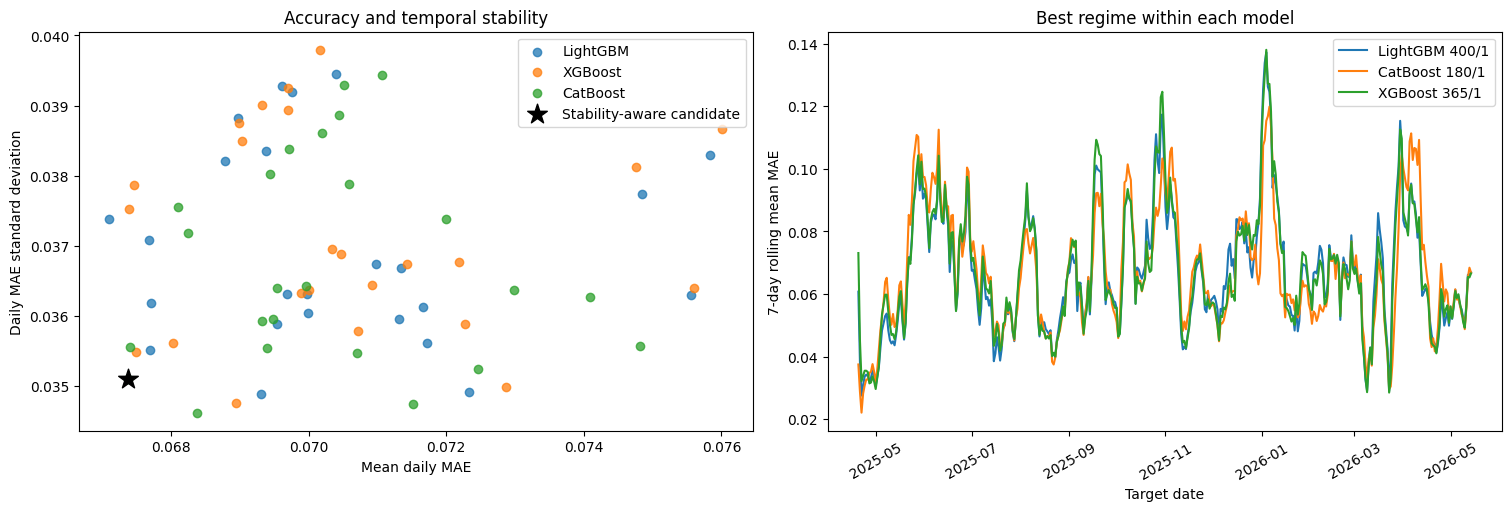

In [8]:
leader = summary.iloc[0]
comparable = summary.loc[summary.mae_mean <= leader.mae_mean * (1 + MAE_RELATIVE_MARGIN)]
recommended = comparable.sort_values(["mae_std", "n_refits", "train_days", "mae_mean"]).iloc[0]
best_by_model = summary.sort_values("mae_mean").groupby("model", sort=False).head(1)

def label(row):
    return f"{row['model']} {int(row['train_days'])}/{int(row['retrain_days'])}"

print(f"Accuracy leader: {label(leader)} | daily MAE={leader.mae_mean:.5f}")
print(f"Stability-aware candidate: {label(recommended)} | daily MAE={recommended.mae_mean:.5f} "
      f"| daily MAE std={recommended.mae_std:.5f} | gap={recommended.mae_gap_pct:.2f}%")
display(best_by_model)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for name in MODEL_NAMES:
    rows = summary.loc[summary.model.eq(name)]
    axes[0].scatter(rows.mae_mean, rows.mae_std, label=name, alpha=0.75)
axes[0].scatter(recommended.mae_mean, recommended.mae_std, marker="*", s=220, color="black", label="Stability-aware candidate")
axes[0].set(xlabel="Mean daily MAE", ylabel="Daily MAE standard deviation", title="Accuracy and temporal stability")
axes[0].legend()
for _, row in best_by_model.iterrows():
    subset = daily.loc[(daily[KEYS] == row[KEYS]).all(axis=1)].sort_values("day").set_index("day")
    axes[1].plot(subset.index, subset.mae.rolling("7D", min_periods=1).mean(), label=label(row))
axes[1].set(xlabel="Target date", ylabel="7-day rolling mean MAE", title="Best regime within each model")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
fig.savefig(OUTPUT_DIR / "accuracy_stability.png", dpi=150)
plt.show()

### Looking at the predictions behind the scores

The selected candidate below is shown with the actual capacity factor. The range slider allows a closer look at ramps and sustained errors. Selection is based on the table above; this plot is a diagnostic, not an extra tuning step.

In [9]:
import plotly.graph_objects as go

selected = predictions.loc[(predictions[KEYS] == recommended[KEYS]).all(axis=1)].sort_values("target_time")
fig = go.Figure()
fig.add_scatter(x=selected.target_time, y=selected.actual, name="Actual CF", mode="lines", line=dict(width=1))
fig.add_scatter(x=selected.target_time, y=selected.prediction, name="Predicted CF", mode="lines", line=dict(width=1))
fig.update_layout(title=f"Out-of-time predictions: {label(recommended)}", template="plotly_white",
                  xaxis=dict(title="Target time (Europe/Berlin)", rangeslider=dict(visible=True)),
                  yaxis_title="Capacity factor", hovermode="x unified", height=500)
fig.write_html(OUTPUT_DIR / "selected_predictions.html", include_plotlyjs=True)
fig.show()
selected.to_parquet(OUTPUT_DIR / "selected_predictions.parquet", index=False)

### Reading the result of this run

The next cell reports the best regime within each model and the practical difference between the two overall candidates. These values are calculated from the results, so they update when the experiment is rerun. The best interval is conditional on the history window and model; a longer history or more frequent retraining does not automatically improve the score.

In [10]:
# Report the empirical result without hard-coding the winning configuration.
for _, row in best_by_model.iterrows():
    print(f"{label(row)}: daily MAE {row.mae_mean:.5f}, "
          f"daily MAE std {row.mae_std:.5f}, pooled R2 {row.r2_pooled:.4f}.")
print()
print(f"The MAE leader is {label(leader)}. The stability-aware candidate is "
      f"{label(recommended)}, with {recommended.mae_gap_pct:.2f}% higher mean daily MAE.")
print(f"Their daily MAE standard deviations are {leader.mae_std:.5f} and "
      f"{recommended.mae_std:.5f}, respectively.")
print(f"The comparison covers {int(leader.n_days)} target days. For the {RETRAIN_INTERVALS[-1]}-day regime, "
      f"this contains only {int(leader.n_days / RETRAIN_INTERVALS[-1])} refits, so evidence about repeated monthly retraining is limited.")

LightGBM 400/1: daily MAE 0.06710, daily MAE std 0.03738, pooled R2 0.8485.
CatBoost 180/1: daily MAE 0.06738, daily MAE std 0.03510, pooled R2 0.8482.
XGBoost 365/1: daily MAE 0.06738, daily MAE std 0.03752, pooled R2 0.8469.

The MAE leader is LightGBM 400/1. The stability-aware candidate is CatBoost 180/1, with 0.41% higher mean daily MAE.
Their daily MAE standard deviations are 0.03738 and 0.03510, respectively.
The comparison covers 390 target days. For the 28-day regime, this contains only 13 refits, so evidence about repeated monthly retraining is limited.


### What this experiment establishes

The table identifies an accuracy leader and a stability-aware candidate **for this evaluation period and these fixed model settings**. It also shows how much accuracy, daily variation, and fitting cost change across all 72 regimes. A small score difference in this short, correlated sample should not be treated as proof of a permanent advantage.

The next step is to freeze a candidate policy, run chronological HPO within its training history, and assess it on the reserved period without using that score to choose another configuration.